# Desafio: PCA no dataset Wine
**Objetivo:** reduzir 13 características químicas a dois componentes e investigar como a padronização muda o resultado.

## 1. Carregar os dados
Usamos o Wine, que reúne 178 amostras de vinho. As classes em `y` serão usadas somente para colorir os gráficos; o PCA aprende a transformação a partir de `X`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA

np.set_printoptions(precision=4, suppress=True)
wine = load_wine()
X = wine.data
y = wine.target

## 2. Explorar o dataset
Conferimos o tamanho dos dados e as escalas das características. As diferenças de desvio padrão ajudam a entender por que a padronização pode alterar o PCA.

In [2]:
print("Formato de X:", X.shape)
print("Classes:", wine.target_names)
print("Quantidade por classe:", np.bincount(y))
print(f"\n{'Característica':<30} {'Média':>10} {'Desvio padrão':>15}")
for nome, media_coluna, desvio in zip(wine.feature_names, X.mean(axis=0), X.std(axis=0)):
    print(f"{nome:<30} {media_coluna:>10.3f} {desvio:>15.3f}")

Formato de X: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']
Quantidade por classe: [59 71 48]

Característica                      Média   Desvio padrão
alcohol                            13.001           0.810
malic_acid                          2.336           1.114
ash                                 2.367           0.274
alcalinity_of_ash                  19.495           3.330
magnesium                          99.742          14.242
total_phenols                       2.295           0.624
flavanoids                          2.029           0.996
nonflavanoid_phenols                0.362           0.124
proanthocyanins                     1.591           0.571
color_intensity                     5.058           2.312
hue                                 0.957           0.228
od280/od315_of_diluted_wines        2.612           0.708
proline                           746.893         314.022


## 3. Centralizar os dados
Subtraímos a média de cada coluna para deslocar o centro dos dados para zero. Nesta primeira análise, mantemos as escalas originais.

In [3]:
media = X.mean(axis=0)
X_centralizado = X - media
print("Médias após centralizar:", np.round(X_centralizado.mean(axis=0), 10))

Médias após centralizar: [ 0.  0. -0.  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]


## 4. Calcular a matriz de covariância
A matriz reúne as variâncias de cada característica e as covariâncias entre elas. Calculamos a matriz completa e exibimos apenas um trecho para facilitar a leitura.

In [4]:
n = len(X)
cov = X_centralizado.T @ X_centralizado / (n - 1)
print("Formato da covariância:", cov.shape)
print("Trecho das três primeiras características:\n", cov[:3, :3])

Formato da covariância: (13, 13)
Trecho das três primeiras características:
 [[0.6591 0.0856 0.0471]
 [0.0856 1.248  0.0503]
 [0.0471 0.0503 0.0753]]


## 5. Calcular e ordenar autovalores e autovetores
Os autovetores indicam as direções dos componentes, e os autovalores medem a variância nessas direções. Ordenamos os valores e as colunas correspondentes, do maior para o menor.

In [5]:
autovalores, autovetores = np.linalg.eigh(cov)
indices = np.argsort(autovalores)[::-1]
autovalores = autovalores[indices]
autovetores = autovetores[:, indices]
print("Autovalores ordenados:\n", autovalores)

Autovalores ordenados:
 [99201.7895   172.5353     9.4381     4.9912     1.2288     0.8411
     0.279      0.1514     0.1121     0.0717     0.0376     0.0211
     0.0082]


## 6. Calcular a variância explicada
Dividimos cada autovalor pela soma de todos eles. A soma acumulada mostra a porcentagem de variância preservada ao manter os primeiros componentes.

In [6]:
evr = autovalores / autovalores.sum()
evr_acumulada = np.cumsum(evr)

print(f"{'Componente':<12} {'Variância (%)':>15} {'Acumulada (%)':>16}")
for i in range(len(evr)):
    print(f"PC{i + 1:<10} {evr[i] * 100:>15.4f} {evr_acumulada[i] * 100:>16.4f}")

Componente     Variância (%)    Acumulada (%)
PC1                  99.8091          99.8091
PC2                   0.1736          99.9827
PC3                   0.0095          99.9922
PC4                   0.0050          99.9972
PC5                   0.0012          99.9985
PC6                   0.0008          99.9993
PC7                   0.0003          99.9996
PC8                   0.0002          99.9997
PC9                   0.0001          99.9999
PC10                  0.0001          99.9999
PC11                  0.0000         100.0000
PC12                  0.0000         100.0000
PC13                  0.0000         100.0000


## 7. Selecionar dois componentes
Guardamos em `W` os dois autovetores de maior autovalor. Seus pesos mostram como as características originais participam de cada componente.

In [7]:
k = 2
W = autovetores[:, :k]
print("Formato de W:", W.shape)
print(f"{'Característica':<30} {'Peso em PC1':>12} {'Peso em PC2':>12}")
for nome, pesos in zip(wine.feature_names, W):
    print(f"{nome:<30} {pesos[0]:>12.4f} {pesos[1]:>12.4f}")

Formato de W: (13, 2)
Característica                  Peso em PC1  Peso em PC2
alcohol                              0.0017       0.0012
malic_acid                          -0.0007       0.0022
ash                                  0.0002       0.0046
alcalinity_of_ash                   -0.0047       0.0265
magnesium                            0.0179       0.9993
total_phenols                        0.0010       0.0009
flavanoids                           0.0016      -0.0001
nonflavanoid_phenols                -0.0001      -0.0014
proanthocyanins                      0.0006       0.0050
color_intensity                      0.0023       0.0151
hue                                  0.0002      -0.0008
od280/od315_of_diluted_wines         0.0007      -0.0035
proline                              0.9998      -0.0178


## 8. Projetar os dados
Multiplicamos os dados centralizados pelos componentes escolhidos. Cada vinho passa a ser representado por duas coordenadas, mantendo as mesmas 178 amostras.

In [8]:
Z = X_centralizado @ W
print("Formato original:", X.shape)
print("Formato reduzido:", Z.shape)
print("Primeiras projeções:\n", Z[:5])

Formato original: (178, 13)
Formato reduzido: (178, 2)
Primeiras projeções:
 [[318.563   21.4921]
 [303.0974  -5.3647]
 [438.0611  -6.5373]
 [733.2401   0.1927]
 [-11.5714  18.49  ]]


## 9. Visualizar a projeção em 2D
Cada ponto representa um vinho. As cores identificam as classes conhecidas apenas para observar a distribuição depois da transformação.

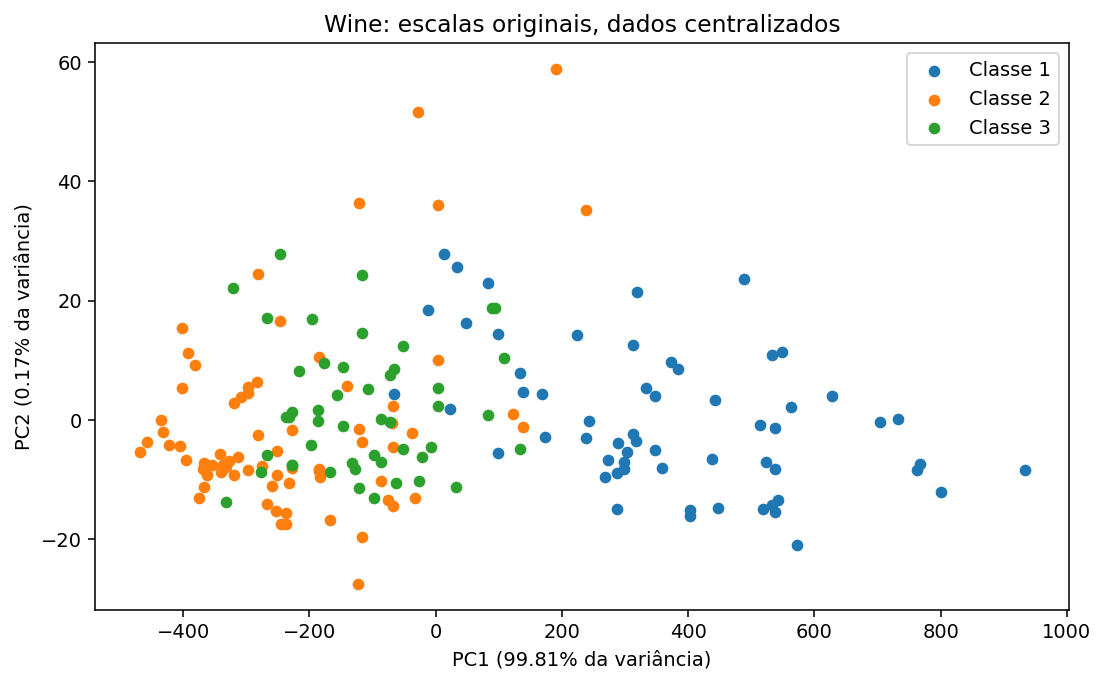

In [9]:
cores = ["tab:blue", "tab:orange", "tab:green"]
plt.figure(figsize=(8, 5))
for grupo in range(len(wine.target_names)):
    plt.scatter(
        Z[y == grupo, 0], Z[y == grupo, 1],
        color=cores[grupo], label=f"Classe {grupo + 1}", s=25
    )
plt.xlabel(f"PC1 ({evr[0]:.2%} da variância)")
plt.ylabel(f"PC2 ({evr[1]:.2%} da variância)")
plt.title("Wine: escalas originais, dados centralizados")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Comparar com o scikit-learn
Usamos os mesmos dados e dois componentes. Como os sinais dos autovetores podem se inverter, alinhamos os sinais antes de comparar as projeções.

In [10]:
pca = PCA(n_components=k, svd_solver="full")
Z_sk = pca.fit_transform(X)
W_sk = pca.components_.T
sinais = np.where(np.sum(W * W_sk, axis=0) < 0, -1, 1)
Z_sk_alinhado = Z_sk * sinais

print("Mesmos autovalores:", np.allclose(autovalores[:k], pca.explained_variance_))
print("Mesma variância explicada:", np.allclose(evr[:k], pca.explained_variance_ratio_))
print("Mesmo subespaço:", np.allclose(W @ W.T, W_sk @ W_sk.T))
print("Mesmas projeções após alinhar sinais:", np.allclose(Z, Z_sk_alinhado))

Mesmos autovalores: True
Mesma variância explicada: True
Mesmo subespaço: True
Mesmas projeções após alinhar sinais: True


## 11. Comparar com os dados padronizados
Agora dividimos as colunas centralizadas por seus desvios padrão e repetimos o PCA. Cada análise calcula sua variância explicada na escala utilizada.

In [11]:
desvio = X.std(axis=0)
X_pad = X_centralizado / desvio
cov_pad = X_pad.T @ X_pad / (n - 1)
autovalores_pad, autovetores_pad = np.linalg.eigh(cov_pad)
indices_pad = np.argsort(autovalores_pad)[::-1]
autovalores_pad = autovalores_pad[indices_pad]
autovetores_pad = autovetores_pad[:, indices_pad]
evr_pad = autovalores_pad / autovalores_pad.sum()
W_pad = autovetores_pad[:, :k]
Z_pad = X_pad @ W_pad

pca_pad = PCA(n_components=k, svd_solver="full")
Z_pad_sk = pca_pad.fit_transform(X_pad)
W_pad_sk = pca_pad.components_.T
sinais_pad = np.where(np.sum(W_pad * W_pad_sk, axis=0) < 0, -1, 1)

print(f"{'Análise':<24} {'PC1 (%)':>10} {'PC2 (%)':>10} {'Total (%)':>12}")
print(f"{'Apenas centralizados':<24} {evr[0]*100:>10.2f} {evr[1]*100:>10.2f} {evr[:k].sum()*100:>12.2f}")
print(f"{'Padronizados':<24} {evr_pad[0]*100:>10.2f} {evr_pad[1]*100:>10.2f} {evr_pad[:k].sum()*100:>12.2f}")
print("EVR padronizada igual à do scikit-learn:", np.allclose(evr_pad[:k], pca_pad.explained_variance_ratio_))
print("Projeção padronizada igual após alinhar sinais:", np.allclose(Z_pad, Z_pad_sk * sinais_pad))

Análise                     PC1 (%)    PC2 (%)    Total (%)
Apenas centralizados          99.81       0.17        99.98
Padronizados                  36.20      19.21        55.41
EVR padronizada igual à do scikit-learn: True
Projeção padronizada igual após alinhar sinais: True


Os gráficos abaixo identificam as duas análises. Os eixos pertencem a representações com escalas diferentes; comparamos os padrões de distribuição das classes.

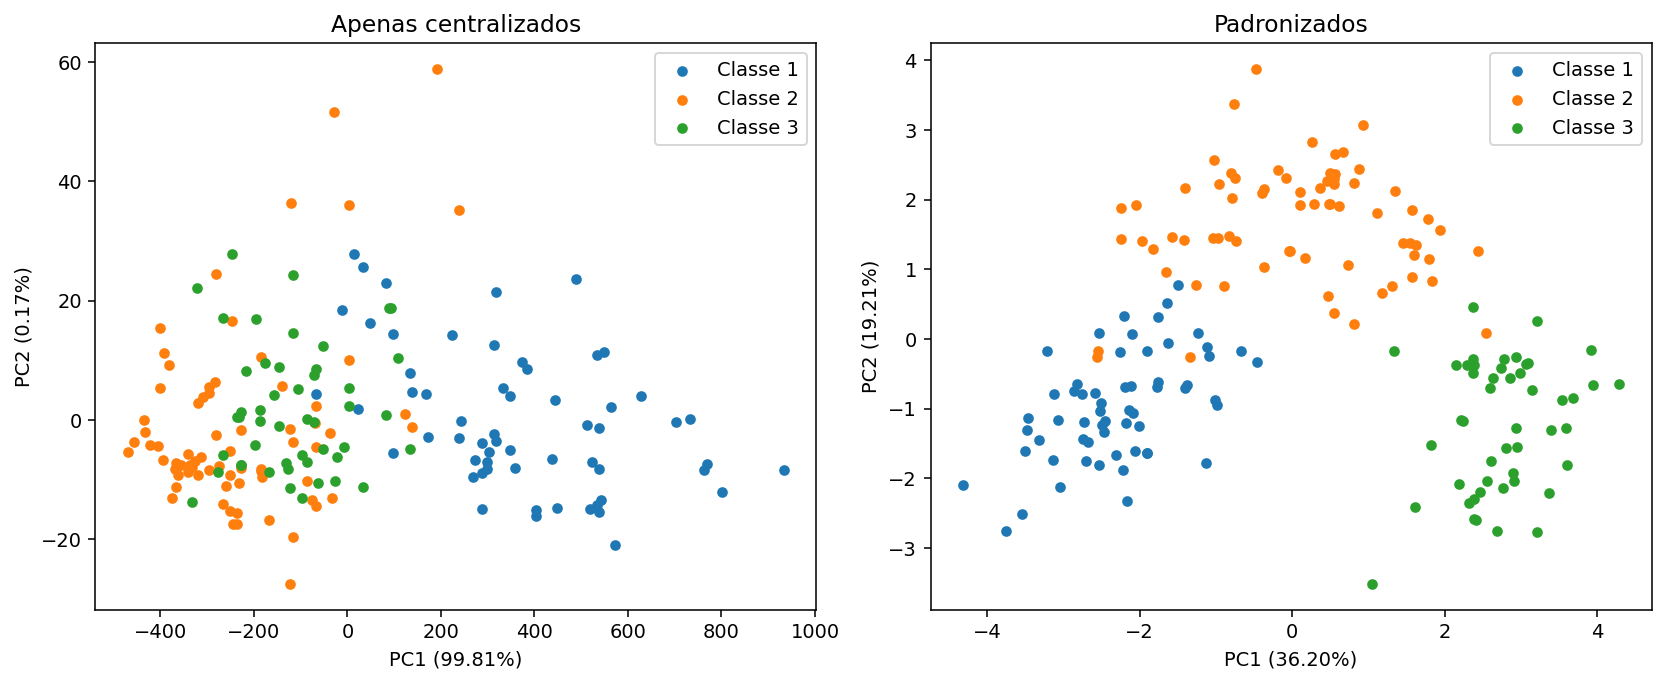

In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
analises = [
    (Z, evr, "Apenas centralizados"),
    (Z_pad, evr_pad, "Padronizados")
]
for eixo, (projecao, proporcao, titulo) in zip(eixos, analises):
    for grupo in range(len(wine.target_names)):
        eixo.scatter(
            projecao[y == grupo, 0], projecao[y == grupo, 1],
            color=cores[grupo], label=f"Classe {grupo + 1}", s=20
        )
    eixo.set_title(titulo)
    eixo.set_xlabel(f"PC1 ({proporcao[0]:.2%})")
    eixo.set_ylabel(f"PC2 ({proporcao[1]:.2%})")
    eixo.legend()
fig.tight_layout()
plt.show()

## 12. Interpretar os resultados
Sem padronização, os dois componentes preservam **99,98%** da variância. O PC1 é dominado por **`proline`**, característica de maior escala numérica neste dataset.

Com padronização, os dois componentes preservam **55,41%** da variância. A variação fica mais distribuída entre os componentes, e o gráfico mostra as três classes mais distintas, ainda com alguma sobreposição.

As porcentagens se referem a escalas diferentes; o percentual maior, sozinho, não determina a melhor representação. As implementações manual e do scikit-learn concordaram nas duas análises. O PCA usou apenas as características; as classes serviram para colorir os gráficos.